# quick MCS classification 
- input: final dataframes (monthly)
- output: 2 D histogram of rain volume and area (used for quick assessment of MCS representativeness in the data)

# load packages 

In [1]:
import numpy as np
import xarray as xr
import os
import pandas as pd

from pathlib import Path

import sys

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Patch
import string

sys.path.append("../tools")
import defs_application


# load data

In [2]:
inputdir = "../output/final_dataframes/"
models = ["ICON","OBS"]
timeperiods = ["JUNE","DECEMBER"]

var_order_anvil_features= defs_application.var_order_anvil_features

In [3]:
## load tracks

ds = {}
for model in models: 
    ds[model] = {}
    for timeperiod in timeperiods: 
        file = os.path.join(inputdir,f"anvil_features_{model}_{timeperiod}.h5")
        Tracks = pd.read_hdf(file, key='table') 
        
        Tracks = Tracks.rename(columns={
            "min_tb": "min_tb_anvil",
            "mean_iwp": "mean_iwp_anvil",
            "max_iwp": "max_iwp_anvil",
            "total_iwp":"total_iwp_anvil",
        })
        ds[model][timeperiod] = Tracks.reset_index()

In [4]:
ds["ICON"]["JUNE"].columns

Index(['index', 'time', 'feature_anvil', 'mean_iwp_anvil', 'total_iwp_anvil',
       'max_iwp_anvil', 'min_tb_anvil', 'area_anvil', 'd_eq_anvil',
       'mean_precip_anvil', 'total_precip_anvil', 'rain_volume_anvil',
       'n_children_anvil', 'iwp_volume_anvil', 'min_dist_anvil_km',
       'convective_rain_volume_anvil',
       'fraction_convection_rain_volume_anvil'],
      dtype='object')

In [5]:
ds[model]["JUNE"]["d_eq_anvil"]

0       586.754045
1       323.464789
2       383.045311
3       120.876512
4       137.904262
           ...    
4803    402.381366
4804    326.511220
4805    362.630790
4806    493.028445
4807    920.777729
Name: d_eq_anvil, Length: 4808, dtype: float64

## rain volume and size

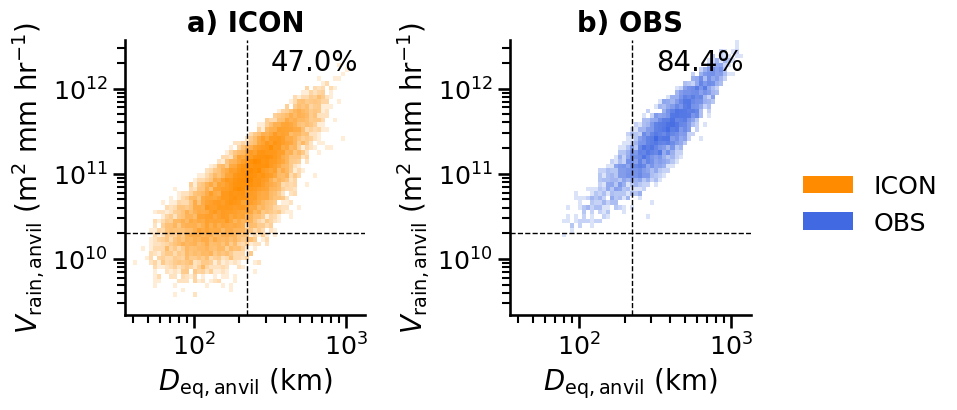

In [7]:
sys.path.append("../tools")
import defs_application

variables = ["d_eq_anvil", "rain_volume_anvil"]
VAR_META_ICON = defs_application.make_var_meta(variables, source="ICON")
VAR_META_OBS = defs_application.make_var_meta(variables, source="OBS")
VAR_META = {"ICON": VAR_META_ICON, "OBS": VAR_META_OBS}

tmpmodels = ["ICON", "OBS"]

deq_threshold = 225
vrain_threshold = 20000000000

x_all = np.concatenate([ds[model]["JUNE"]["d_eq_anvil"] for model in tmpmodels])
y_all = np.concatenate([ds[model]["JUNE"]["rain_volume_anvil"] for model in tmpmodels])
x_min, x_max = np.nanmin(x_all), np.nanmax(x_all)
y_min, y_max = np.nanmin(y_all), np.nanmax(y_all)

x_floor = 1e-2  
y_floor = 1e-2  
x_min = max(x_min, x_floor)
y_min = max(y_min, y_floor)

# Log-spaced bin edges 
n_bins = 60
x_bins = np.logspace(np.log10(x_min), np.log10(x_max), n_bins + 1)
y_bins = np.logspace(np.log10(y_min), np.log10(y_max), n_bins + 1)

sns.set_context("talk", font_scale = 1.1)
fig, ax = plt.subplots(1, 2, figsize=(8, 4.5))
for i, (axis, model) in enumerate(zip(ax, tmpmodels)):
    x = ds[model]["JUNE"]["d_eq_anvil"]
    y = ds[model]["JUNE"]["rain_volume_anvil"]
    meta_x = VAR_META[model]["d_eq_anvil"]
    meta_y = VAR_META[model]["rain_volume_anvil"]

    model_color = defs_application.coloricon if model == "ICON" else defs_application.colorobs
    cmap = LinearSegmentedColormap.from_list(f"{model}_cmap", ["white", model_color])
    axis.hist2d(
        x, y,
        bins=[x_bins, y_bins],
        norm=LogNorm(),
        cmap=cmap,
    )
    axis.set_xlim(x_min, x_max)
    axis.set_ylim(y_min, y_max)
    axis.set_yscale("log")
    axis.set_xscale("log")
    

    if deq_threshold is not None and vrain_threshold is not None:
        axis.axvline(deq_threshold, color="black", linestyle="--", linewidth=1)
        axis.axhline(vrain_threshold, color="black", linestyle="--", linewidth=1)
        n_total = len(x)
        n_match = ((x >= deq_threshold) & (y >= vrain_threshold)).sum()
        pct_match = 100 * n_match / n_total
        axis.text(
            0.97, 0.97, f"{pct_match:.1f}%",
            transform=axis.transAxes,
            ha="right", va="top",
            color="black",
        )
    panel_label = string.ascii_lowercase[i]
    axis.set_title(f"{panel_label}) {model}", fontweight="bold")
    axis.set_xlabel(f"{meta_x['label']} ({meta_x['unit']})")
    axis.set_ylabel(f"{meta_y['label']} ({meta_y['unit']})")

legend_handles = [
    Patch(facecolor=defs_application.coloricon, label="ICON"),
    Patch(facecolor=defs_application.colorobs, label="OBS"),
]
fig.legend(
    handles=legend_handles,
   loc="center left",
    ncol=1,
    frameon=False,
    bbox_to_anchor=(1, 0.5),
)
sns.despine()
plt.tight_layout()#rect=[0, 0.1, 1, 1])
plt.savefig("../output/plots/Vrain_Deq_scatter_plots.pdf", bbox_inches="tight",
            pad_inches=0.02)
plt.show()